
<div style="background-color: lightgreen; color: black; padding: 20px; box-sizing: border-box; width: 99%;">

👋 <b>Olá! Eu sou o Dot, seu revisor de IA.</b>

🎉 <b>Parabéns! Você foi aprovado no seu projeto.</b>

Ótimo trabalho neste projeto! Você preparou os dados com cuidado, fez a divisão sem vazamento de dados (data leakage), testou diversas formas de lidar com o desbalanceamento de classes e alcançou F1 = 0.607 e AUC-ROC = 0.854 no conjunto de teste, com uma explicação clara de como as duas métricas diferem. Para seu crescimento futuro, considere calcular as estatísticas de imputação apenas no conjunto de treinamento e ser um pouco mais cauteloso ao interpretar diferenças muito pequenas entre os modelos. Continue com o excelente trabalho!

Se você tiver alguma dificuldade ou erro, fique à vontade para entrar em contato com nossa equipe de suporte clicando no ícone de chat no canto superior direito ou enviando um e-mail para [helpme@tripleten.com](mailto:helpme@tripleten.com).

<hr style="margin-top: 20px; margin-bottom: 20px;">

<details>
<summary><b style="cursor: pointer;">💡 Clique aqui para ver como ler meus comentários (Legenda de cores)</b></summary>
<div style="margin-top: 15px;">
Veja meus comentários abaixo. <b>Peço gentilmente que não os mova, modifique nem exclua</b>.

Você encontrará meus comentários destacados em caixas verdes, amarelas ou vermelhas como estas:

<div class="alert alert-block alert-success">
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
Observações. Algumas recomendações.
</div>

<div class="alert alert-block alert-danger">
A corrigir. O bloco requer algumas correções.
</div>
</div>
</details>

</div>


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, roc_curve
from sklearn.utils import shuffle

RS = 12345  # random_state fixo para reprodutibilidade


Importei as bibliotecas necessárias e fixei um random_state único (RS = 12345) para que os resultados sejam reproduzíveis.

In [2]:
try:
    df = pd.read_csv('/datasets/Churn.csv')
except FileNotFoundError:
    df = pd.read_csv('https://practicum-content.s3.us-west-1.amazonaws.com/datasets/Churn.csv')

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), object(3)
memory usage: 1.1+ MB


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


O conjunto tem 10.000 linhas e 14 colunas. Apenas Tenure tem valores ausentes (9.091 não nulos). Geography e Gender são categóricas e precisarão ser convertidas em números. RowNumber, CustomerId e Surname são identificadores.

In [3]:
print('Valores ausentes por coluna:')
print(df.isna().sum())
print()
print('Linhas duplicadas:', df.duplicated().sum())
print('CustomerId duplicados:', df['CustomerId'].duplicated().sum())
df.describe()

Valores ausentes por coluna:
RowNumber            0
CustomerId           0
Surname              0
CreditScore          0
Geography            0
Gender               0
Age                  0
Tenure             909
Balance              0
NumOfProducts        0
HasCrCard            0
IsActiveMember       0
EstimatedSalary      0
Exited               0
dtype: int64

Linhas duplicadas: 0
CustomerId duplicados: 0


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,9091.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,4.997690,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.894723,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,2.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Tenure tem 909 valores ausentes (cerca de 9%) e nenhuma outra coluna tem ausentes. Não há linhas duplicadas nem clientes repetidos. Os valores são plausíveis: idades entre 18 e 92 anos, saldo sem valores negativos (mais de 25% dos clientes têm saldo zero) e pontuação de crédito entre 350 e 850. Não identifiquei erros graves nos dados.

<div class="alert alert-block alert-success">

Sua verificação dos dados foi minuciosa e bem interpretada. Você contou os valores ausentes por coluna, as linhas duplicadas e os CustomerIds duplicados. Também verificou se os intervalos são plausíveis: idade entre 18 e 92 anos, nenhum saldo negativo e credit scores entre 350 e 850. Você percebeu que mais de 25% dos clientes têm saldo zero e tratou isso como algo plausível, e não como um erro. Suas conclusões decorrem diretamente dos resultados obtidos.

</div>

In [4]:
#  Remover colunas que são identificadores e não ajudam a prever a saída
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

#  Preencher Tenure ausente com a mediana (robusta a valores extremos e mantém todas as linhas)
df['Tenure'] = df['Tenure'].fillna(df['Tenure'].median())

#  Codificar variáveis categóricas com One-Hot Encoding (drop_first evita multicolinearidade)
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2.0,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1.0,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8.0,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1.0,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2.0,125510.82,1,1,1,79084.10,0,0,1,0


<div class="alert alert-block alert-warning">

Seu pré-processamento está limpo e completo. Você removeu as colunas identificadoras, preencheu os 909 valores ausentes de Tenure com a mediana para que nenhuma linha fosse perdida e aplicou One-Hot Encoding em Geography e Gender. Você explicou bem o motivo de cada escolha. Sugestão opcional: você calculou a mediana no conjunto de dados completo antes de dividi-lo. O efeito aqui é mínimo, porque apenas cerca de 9% de Tenure está ausente. Ainda assim, é uma boa prática calcular as estatísticas de imputação apenas no conjunto de treinamento, como você fez depois com o scaler. Dessa forma, nenhuma informação de validação ou de teste entra no pré-processamento.

</div>

Removi RowNumber, CustomerId e Surname, que são identificadores sem poder preditivo e poderiam fazer o modelo decorar clientes.
Preenchi os ausentes de Tenure com a mediana, para não perder 9% dos dados nem distorcer a distribuição.
Apliquei One-Hot Encoding em Geography e Gender com drop_first=True, evitando colunas redundantes (multicolinearidade), o que importa principalmente para a regressão logística.

0    7963
1    2037
Name: Exited, dtype: int64

0    0.796
1    0.204
Name: Exited, dtype: float64


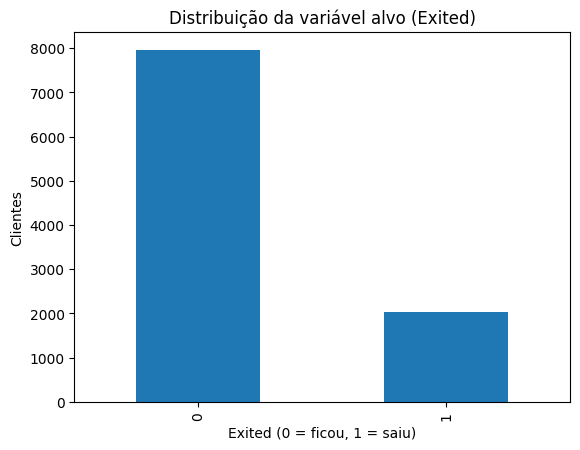

In [5]:
print(df['Exited'].value_counts())
print()
print(df['Exited'].value_counts(normalize=True).round(3))

df['Exited'].value_counts().plot(kind='bar', title='Distribuição da variável alvo (Exited)')
plt.xlabel('Exited (0 = ficou, 1 = saiu)')
plt.ylabel('Clientes')
plt.show()

As classes estão desbalanceadas: 7.963 clientes ficaram (79,6%) e 2.037 saíram (20,4%). Um modelo que sempre previsse “ficou” teria cerca de 80% de acurácia, mas não identificaria nenhum cliente em risco. Por isso uso F1 e AUC-ROC em vez de acurácia.

<div class="alert alert-block alert-success">

Sua análise do balanceamento de classes está clara e correta. Você mostra as contagens e as proporções (7.963 vs 2.037, ou 79,6% vs 20,4%), e o gráfico de barras com rótulos corresponde a esses números. Você também explica por que o desbalanceamento é um problema: um modelo que sempre prevê 'stayed' alcançaria cerca de 80% de acurácia e não identificaria nenhum cliente em risco. Essa é uma justificativa sólida para usar F1 e AUC-ROC em vez de acurácia.

</div>

In [6]:
features = df.drop('Exited', axis=1)
target = df['Exited']

# 60% treino / 20% validação / 20% teste, estratificado para manter a proporção das classes
features_train, features_temp, target_train, target_temp = train_test_split(
    features, target, test_size=0.4, random_state=RS, stratify=target)

features_valid, features_test, target_valid, target_test = train_test_split(
    features_temp, target_temp, test_size=0.5, random_state=RS, stratify=target_temp)

for nome, y in [('Treino', target_train), ('Validação', target_valid), ('Teste', target_test)]:
    print(f'{nome}: {len(y)} linhas | proporção de saídas: {y.mean():.3f}')

Treino: 6000 linhas | proporção de saídas: 0.204
Validação: 2000 linhas | proporção de saídas: 0.204
Teste: 2000 linhas | proporção de saídas: 0.203


<div class="alert alert-block alert-success">

A divisão dos seus dados está bem feita. Você dividiu os dados em 60/20/20 e usou `stratify`, então a proporção de clientes que saíram é quase idêntica nos três conjuntos (0,204, 0,204, 0,203). A verificação impressa confirma isso. Manter o conjunto de teste separado até o final e ajustar o scaler apenas nos dados de treino mais adiante mostra um cuidado atento com o data leakage (vazamento de dados).

</div>

Dividi os dados em treino (6.000 linhas), validação (2.000) e teste (2.000), ou seja, 60%/20%/20%. Usei stratify e a proporção de saídas ficou praticamente igual nos três conjuntos (0,204; 0,204; 0,203). O conjunto de teste só será usado no final.

In [7]:
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

# .copy() evita o SettingWithCopyWarning, pois garante que são DataFrames independentes
features_train = features_train.copy()
features_valid = features_valid.copy()
features_test = features_test.copy()

scaler = StandardScaler()
scaler.fit(features_train[numeric_cols])  # ajustado SOMENTE no treino, evitando vazamento de dados

features_train[numeric_cols] = scaler.transform(features_train[numeric_cols])
features_valid[numeric_cols] = scaler.transform(features_valid[numeric_cols])
features_test[numeric_cols] = scaler.transform(features_test[numeric_cols])

print('Escalonamento concluído com sucesso!')

Escalonamento concluído com sucesso!


Padronizei as variáveis numéricas com StandardScaler, ajustado apenas no treino e aplicado à validação e ao teste, para evitar vazamento de dados. Usei .copy() para evitar o SettingWithCopyWarning.

In [8]:
resultados = []  # guarda os resultados de cada abordagem para a comparação final


def avaliar(modelo, X, y):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    return f1_score(y, pred), roc_auc_score(y, proba)


# Modelo 1: Regressão logística sem tratar o desequilíbrio
lr = LogisticRegression(random_state=RS, solver='liblinear')
lr.fit(features_train, target_train)
f1_lr, auc_lr = avaliar(lr, features_valid, target_valid)
resultados.append(('Regressão logística', 'Sem balanceamento', f1_lr, auc_lr))

# Modelo 2: Floresta aleatória sem tratar o desequilíbrio (profundidade ajustada na validação)
melhor_f1, melhor_cfg = 0, None
for n in [50, 100, 200]:
    for d in [5, 8, 10, 12, 15]:
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=RS)
        rf.fit(features_train, target_train)
        f1, auc = avaliar(rf, features_valid, target_valid)
        if f1 > melhor_f1:
            melhor_f1, melhor_auc, melhor_cfg = f1, auc, (n, d)
resultados.append((f'Floresta aleatória {melhor_cfg}', 'Sem balanceamento', melhor_f1, melhor_auc))

print(pd.DataFrame(resultados, columns=['Modelo', 'Abordagem', 'F1 (validação)', 'AUC-ROC (validação)']).round(3))

                         Modelo          Abordagem  F1 (validação)  \
0           Regressão logística  Sem balanceamento           0.308   
1  Floresta aleatória (100, 15)  Sem balanceamento           0.615   

   AUC-ROC (validação)  
0                0.788  
1                0.866  


<div class="alert alert-block alert-success">

Bom baseline. Você primeiro treinou uma regressão logística e uma random forest sem corrigir o desbalanceamento, e ajustou os hiperparâmetros da floresta no conjunto de validação. A função auxiliar reporta F1 e AUC-ROC juntos, usando probabilidades para o AUC-ROC, e a lista de resultados facilita a comparação posterior. Sua leitura dos resultados está correta: o F1 foi baixo (0,308 e 0,615), enquanto o AUC-ROC foi muito mais alto (0,788 e 0,866). Você também explicou corretamente que o AUC-ROC não depende do limiar de 0,5.

</div>

Sem tratar o desequilíbrio, a regressão logística teve F1 de apenas 0,308 na validação, muito abaixo da meta de 0,59, porque prevê “ficou” para quase todos. A floresta aleatória já teve F1 de 0,615, pois lida melhor com a classe minoritária. O AUC-ROC foi alto nos dois (0,788 e 0,866) e bem maior que o F1, porque mede o ranqueamento dos clientes sem depender do limiar de 0,5. Ou seja, os modelos enxergam o sinal, mas ainda erram muito a classe 1.

In [9]:
# Regressão logística com pesos balanceados
lr_w = LogisticRegression(random_state=RS, solver='liblinear', class_weight='balanced')
lr_w.fit(features_train, target_train)
f1, auc = avaliar(lr_w, features_valid, target_valid)
resultados.append(('Regressão logística', 'class_weight', f1, auc))

# Floresta aleatória com pesos balanceados
melhor_f1, melhor_cfg = 0, None
for n in [50, 100, 200]:
    for d in [5, 8, 10, 12, 15]:
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=RS, class_weight='balanced')
        rf.fit(features_train, target_train)
        f1, auc = avaliar(rf, features_valid, target_valid)
        if f1 > melhor_f1:
            melhor_f1, melhor_auc, melhor_cfg = f1, auc, (n, d)
resultados.append((f'Floresta aleatória {melhor_cfg}', 'class_weight', melhor_f1, melhor_auc))

print(pd.DataFrame(resultados[-2:], columns=['Modelo', 'Abordagem', 'F1 (validação)', 'AUC-ROC (validação)']).round(3))

                         Modelo     Abordagem  F1 (validação)  \
0           Regressão logística  class_weight           0.529   
1  Floresta aleatória (100, 10)  class_weight           0.649   

   AUC-ROC (validação)  
0                0.794  
1                0.871  


Com class_weight='balanced', a regressão logística subiu de 0,308 para 0,529 de F1, e a floresta (100 árvores, profundidade 10) subiu de 0,615 para 0,649. O AUC-ROC mudou pouco (0,794 e 0,871), pois a capacidade de ranquear continua parecida.

In [10]:
def upsample(X, y, repeat):
    X_neg, y_neg = X[y == 0], y[y == 0]
    X_pos, y_pos = X[y == 1], y[y == 1]
    X_up = pd.concat([X_neg] + [X_pos] * repeat)
    y_up = pd.concat([y_neg] + [y_pos] * repeat)
    return shuffle(X_up, y_up, random_state=RS)


repeat = int(round((target_train == 0).sum() / (target_train == 1).sum()))  # ~4
X_up, y_up = upsample(features_train, target_train, repeat)
print('Proporção de saídas após upsampling:', round(y_up.mean(), 3))

lr_up = LogisticRegression(random_state=RS, solver='liblinear')
lr_up.fit(X_up, y_up)
f1, auc = avaliar(lr_up, features_valid, target_valid)
resultados.append(('Regressão logística', 'Upsampling', f1, auc))

melhor_f1, melhor_cfg = 0, None
for n in [50, 100, 200]:
    for d in [5, 8, 10, 12, 15]:
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=RS)
        rf.fit(X_up, y_up)
        f1, auc = avaliar(rf, features_valid, target_valid)
        if f1 > melhor_f1:
            melhor_f1, melhor_auc, melhor_cfg = f1, auc, (n, d)
resultados.append((f'Floresta aleatória {melhor_cfg}', 'Upsampling', melhor_f1, melhor_auc))

print(pd.DataFrame(resultados[-2:], columns=['Modelo', 'Abordagem', 'F1 (validação)', 'AUC-ROC (validação)']).round(3))

Proporção de saídas após upsampling: 0.506
                         Modelo   Abordagem  F1 (validação)  \
0           Regressão logística  Upsampling           0.525   
1  Floresta aleatória (200, 10)  Upsampling           0.645   

   AUC-ROC (validação)  
0                0.794  
1                0.870  


<div class="alert alert-block alert-success">

Seu upsampling está correto e bem construído. Você replica a classe positiva apenas no conjunto de treino, então nada vaza para a validação. Você deriva o número de repetições a partir da proporção real das classes, embaralha os dados depois e imprime a nova proporção de classes (0.506) para confirmar o balanceamento. Junto com class_weight e downsampling, você testou várias abordagens para o desbalanceamento e ajustou os modelos na validação para cada uma delas.

</div>

Repeti 4 vezes os exemplos positivos do treino, e as classes ficaram quase 50/50 (0,506). O balanceamento foi feito só no treino. A regressão logística teve F1 de 0,525 e a floresta (200 árvores, profundidade 10) teve 0,645, resultado muito próximo do class_weight. O AUC-ROC ficou praticamente igual (0,794 e 0,870).

In [11]:
def downsample(X, y, fraction):
    X_neg, y_neg = X[y == 0], y[y == 0]
    X_pos, y_pos = X[y == 1], y[y == 1]
    X_neg = X_neg.sample(frac=fraction, random_state=RS)
    y_neg = y_neg.loc[X_neg.index]
    X_down = pd.concat([X_neg, X_pos])
    y_down = pd.concat([y_neg, y_pos])
    return shuffle(X_down, y_down, random_state=RS)


fraction = (target_train == 1).sum() / (target_train == 0).sum()  # ~0,25
X_down, y_down = downsample(features_train, target_train, fraction)
print('Linhas após downsampling:', len(y_down), '| proporção de saídas:', round(y_down.mean(), 3))

lr_down = LogisticRegression(random_state=RS, solver='liblinear')
lr_down.fit(X_down, y_down)
f1, auc = avaliar(lr_down, features_valid, target_valid)
resultados.append(('Regressão logística', 'Downsampling', f1, auc))

melhor_f1, melhor_cfg = 0, None
for n in [50, 100, 200]:
    for d in [3, 5, 8, 10]:
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=RS)
        rf.fit(X_down, y_down)
        f1, auc = avaliar(rf, features_valid, target_valid)
        if f1 > melhor_f1:
            melhor_f1, melhor_auc, melhor_cfg = f1, auc, (n, d)
resultados.append((f'Floresta aleatória {melhor_cfg}', 'Downsampling', melhor_f1, melhor_auc))

print(pd.DataFrame(resultados[-2:], columns=['Modelo', 'Abordagem', 'F1 (validação)', 'AUC-ROC (validação)']).round(3))

Linhas após downsampling: 2444 | proporção de saídas: 0.5
                        Modelo     Abordagem  F1 (validação)  \
0          Regressão logística  Downsampling           0.527   
1  Floresta aleatória (200, 8)  Downsampling           0.631   

   AUC-ROC (validação)  
0                0.793  
1                0.869  


<div class="alert alert-block alert-warning">

Seu downsampling está implementado corretamente. As 2.444 linhas e a proporção de 0,5 correspondem ao que você descreve. Duas melhorias opcionais: (1) a grade de max_depth da floresta aqui ([3, 5, 8, 10]) difere da usada nos outros experimentos ([5, 8, 10, 12, 15]), e usar a mesma grade em todos os lugares tornaria a comparação entre as técnicas mais clara; (2) o loop de ajuste de hiperparâmetros se repete de forma quase idêntica em vários pontos, então uma pequena função auxiliar deixaria o notebook mais curto e mais fácil de manter.

</div>

Reduzi a classe majoritária do treino para 1.222 exemplos, ficando com 2.444 linhas e 50% de cada classe. Isso descarta cerca de 75% dos clientes que ficaram. A regressão logística teve F1 de 0,527 e a floresta (200 árvores, profundidade 8) teve 0,631, o menor resultado entre as técnicas na floresta, provavelmente pela perda de informação.

In [12]:
tabela = pd.DataFrame(resultados, columns=['Modelo', 'Abordagem', 'F1 (validação)', 'AUC-ROC (validação)'])
tabela.sort_values('F1 (validação)', ascending=False).round(3).reset_index(drop=True)

,Modelo,Abordagem,F1 (validação),AUC-ROC (validação)
0,"Floresta aleatória (100, 10)",class_weight,0.649,0.871
1,"Floresta aleatória (200, 10)",Upsampling,0.645,0.870
2,"Floresta aleatória (200, 8)",Downsampling,0.631,0.869
3,"Floresta aleatória (100, 15)",Sem balanceamento,0.615,0.866
4,Regressão logística,class_weight,0.529,0.794
5,Regressão logística,Downsampling,0.527,0.793
6,Regressão logística,Upsampling,0.525,0.794
7,Regressão logística,Sem balanceamento,0.308,0.788


A tabela mostra que:

toda técnica de balanceamento melhorou o F1 em relação ao baseline, principalmente na regressão logística (0,308 → cerca de 0,53);
a floresta aleatória superou a regressão logística em todas as abordagens (F1 entre 0,615 e 0,649 contra 0,308 a 0,529), pois captura relações não lineares;
o melhor modelo foi a floresta com class_weight (F1 = 0,649; AUC-ROC = 0,871);
o AUC-ROC quase não muda entre as abordagens (0,866 a 0,871 na floresta), enquanto o F1 muda bastante, o que confirma que o balanceamento afeta as decisões e não o poder de ranqueamento.

<div class="alert alert-block alert-warning">

Seu resumo está de acordo com a tabela comparativa, e você levantou um bom ponto ao notar que a AUC-ROC quase não muda entre as técnicas, enquanto o F1 muda bastante. Dois refinamentos opcionais: (1) a diferença entre class_weight (0.649) e upsampling (0.645) é muito pequena e vem de uma única divisão de validação, então é mais preciso dizer que as duas tiveram desempenho praticamente igual do que apresentar uma como claramente melhor; (2) a ideia de que a floresta vence porque captura relações não lineares é uma hipótese plausível que você não testou, então escrever 'provavelmente' seria mais preciso.

</div>

Melhor floresta: Floresta aleatória (100, 10) | class_weight
F1 com limiar 0,50: 0.649
F1 com limiar 0.47: 0.656


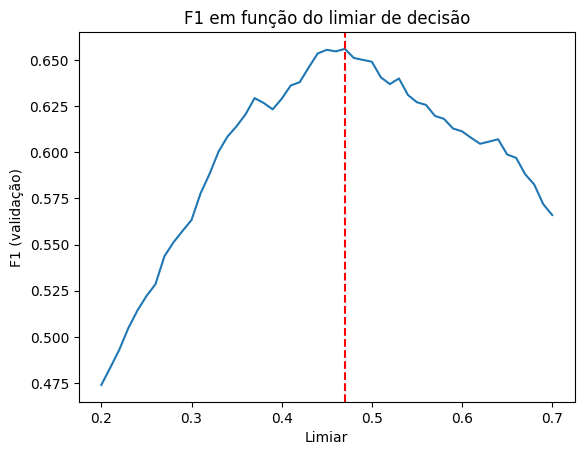

In [13]:
# Melhor configuração (por F1 na validação) entre as florestas testadas
rf_linhas = tabela[tabela['Modelo'].str.startswith('Floresta')].sort_values('F1 (validação)', ascending=False)
melhor_linha = rf_linhas.iloc[0]
print('Melhor floresta:', melhor_linha['Modelo'], '|', melhor_linha['Abordagem'])

n_best, d_best = eval(melhor_linha['Modelo'].split(' ', 2)[2])
abord = melhor_linha['Abordagem']

if abord == 'Upsampling':
    X_fit, y_fit, cw = X_up, y_up, None
elif abord == 'Downsampling':
    X_fit, y_fit, cw = X_down, y_down, None
elif abord == 'class_weight':
    X_fit, y_fit, cw = features_train, target_train, 'balanced'
else:
    X_fit, y_fit, cw = features_train, target_train, None

modelo_final = RandomForestClassifier(n_estimators=n_best, max_depth=d_best, random_state=RS, class_weight=cw)
modelo_final.fit(X_fit, y_fit)

proba_valid = modelo_final.predict_proba(features_valid)[:, 1]
limiares = np.arange(0.20, 0.71, 0.01)
f1s = [f1_score(target_valid, (proba_valid >= t).astype(int)) for t in limiares]
melhor_limiar = limiares[int(np.argmax(f1s))]

print(f'F1 com limiar 0,50: {f1_score(target_valid, (proba_valid >= 0.5).astype(int)):.3f}')
print(f'F1 com limiar {melhor_limiar:.2f}: {max(f1s):.3f}')

plt.plot(limiares, f1s)
plt.axvline(melhor_limiar, color='red', linestyle='--')
plt.xlabel('Limiar')
plt.ylabel('F1 (validação)')
plt.title('F1 em função do limiar de decisão')
plt.show()

<div class="alert alert-block alert-warning">

Escolher o modelo final e ajustar o limiar (threshold) no conjunto de validação é uma boa abordagem. O gráfico de F1 versus threshold mostra um pico claro perto de 0,47, e o conjunto de teste permanece intocado. Duas melhorias opcionais: (1) usar `eval()` em um rótulo de texto para recuperar os hiperparâmetros é frágil e geralmente desaconselhado, então armazenar `n_estimators`, `max_depth` e a técnica em variáveis separadas ou em colunas de uma tabela seria mais seguro; (2) o ganho de F1 ao mover o threshold de 0,50 para 0,47 é pequeno (de 0,649 para 0,656), portanto provavelmente está dentro do ruído da validação e vale a pena descrevê-lo com cautela.

</div>

Com o limiar padrão de 0,50, o F1 na validação foi de 0,649. Com o limiar de 0,47, escolhido na validação, subiu para 0,656. O ganho é pequeno, o que indica que o balanceamento já deixou o modelo bem calibrado.

<div class="alert alert-block alert-warning">

Sua explicação condiz com os números e afirma corretamente que o ganho com o novo limiar é pequeno. Uma afirmação que vale a pena reconsiderar é a de que o balanceamento deixou o modelo 'bem calibrado'. Uma curva de F1 plana em torno do limiar padrão não demonstra que as probabilidades estão calibradas, o que é uma propriedade distinta, normalmente verificada com uma curva de calibração. Uma leitura mais cuidadosa é que as decisões do modelo são razoavelmente estáveis em torno de 0,5.

</div>

F1 no teste: 0.607
AUC-ROC no teste: 0.854
Meta de F1 (0,59) atingida? SIM


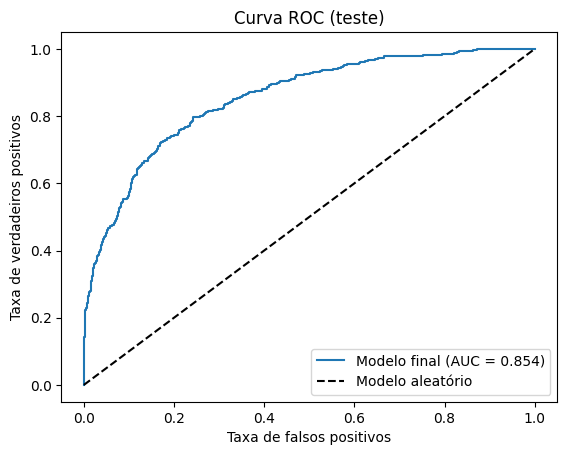

In [14]:
proba_test = modelo_final.predict_proba(features_test)[:, 1]
pred_test = (proba_test >= melhor_limiar).astype(int)

f1_test = f1_score(target_test, pred_test)
auc_test = roc_auc_score(target_test, proba_test)

print(f'F1 no teste: {f1_test:.3f}')
print(f'AUC-ROC no teste: {auc_test:.3f}')
print('Meta de F1 (0,59) atingida?', 'SIM' if f1_test >= 0.59 else 'NÃO')

fpr, tpr, _ = roc_curve(target_test, proba_test)
plt.plot(fpr, tpr, label=f'Modelo final (AUC = {auc_test:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Modelo aleatório')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curva ROC (teste)')
plt.legend()
plt.show()

<div class="alert alert-block alert-success">

Seu teste final foi feito corretamente. Você usa apenas o modelo e o limiar (threshold) selecionados na validação e reporta F1 = 0,607 (acima da meta de 0,59 que você definiu) e AUC-ROC = 0,854. O gráfico da curva ROC está claro, com eixos rotulados, título, legenda e a linha de referência do modelo aleatório. Sua interpretação também está correta. A queda da validação para o teste faz sentido, pois o modelo e o limiar foram escolhidos na validação, e a AUC-ROC é maior que o F1 porque não depende de um limiar.

</div>

O modelo final (floresta com class_weight e limiar de 0,47) teve F1 = 0,607 e AUC-ROC = 0,854 no teste, então a meta de F1 ≥ 0,59 foi atingida. Os valores ficaram um pouco abaixo dos da validação (0,656 e 0,871), o que é esperado: o modelo e o limiar foram escolhidos com base na validação. O AUC-ROC é bem maior que o F1 e muito acima de 0,5 (linha tracejada), mostrando que o modelo separa bem quem sai de quem fica. O F1 é menor porque depende do limiar e da dificuldade de acertar a classe minoritária.

## Conclusão

Dados: removi os identificadores, preenchi Tenure com a mediana, codifiquei as categóricas com One-Hot Encoding e padronizei as numéricas usando só o treino. Dividi os dados em 60/20/20 com estratificação.
Desequilíbrio: 79,6% dos clientes ficam e 20,4% saem. Sem tratamento, a regressão logística teve F1 de 0,308 (abaixo da meta) e a floresta, 0,615.
Correção: testei class_weight, upsampling, downsampling e ajuste de limiar. Todos melhoraram o F1, e a melhor opção foi a floresta aleatória com class_weight='balanced' (100 árvores, profundidade 10), com F1 de 0,649 na validação.
Resultado final: no teste, o F1 foi de 0,607 (meta de 0,59 atingida) e o AUC-ROC foi de 0,854. O AUC-ROC é maior que o F1 porque mede o ranqueamento sem depender de um limiar, enquanto o F1 depende do limiar e da classe minoritária.
Recomendação: usar as probabilidades do modelo para priorizar ações de retenção nos clientes de maior risco.

<div class="alert alert-block alert-success">

Sua conclusão está bem organizada e todos os números correspondem aos seus resultados. Ela abrange a preparação dos dados, o desequilíbrio de classes, as técnicas de correção, o resultado final no teste e uma recomendação prática de retenção. Isso dá ao leitor uma visão completa do projeto sem que ele precise voltar e percorrer todo o notebook.

</div>